# 02 — Base balanceada para o modelo

**Objetivo:** gerar a base que o modelo vai usar, com o mesmo número de fraudes e de legítimas no treino (recomendação do professor), sem cair nas armadilhas do balanceamento.

**A ordem importa:**

| Passo | O que faz | Por que nessa ordem |
|---|---|---|
| 1 | Seleciona as colunas (a partir da triagem do notebook 01) | Trabalhar só com o que tem sinal e não vaza |
| 2 | Cria as features **na base inteira** | "Valor ÷ média do cartão" precisa de todo o histórico. Depois do sorteio, ele some |
| 3 | Separa um **teste com proporção real** (~0,1% de fraude) | Num teste 50/50, o modelo parece ótimo e falha no mundo real |
| 4 | Monta o **treino balanceado 1:1** | Fraudes do treino + o mesmo número de legítimas sorteadas |
| 5 | Confere se as legítimas sorteadas representam a base | Evita que o sorteio pegue só compras "fáceis" |
| 6 | Salva os arquivos | `data/processed/` |

## 1. Carga e seleção de colunas

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
PROC = DATA / "processed"
PROC.mkdir(exist_ok=True)

SEMENTE = 42                # fixa o sorteio: todos do grupo geram a mesma base
PROPORCAO_TESTE = 0.20      # 20% das fraudes (e das legítimas) vão para o teste
RAZAO_LEGIT_POR_FRAUDE = 1  # 1 = balanceado 1:1. Teste 5 ou 10 para comparar

COR_LEGIT, COR_FRAUDE = "#2a78d6", "#eb6834"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

df = pd.read_pickle(DATA / "transacoes.pkl")
df["feedback_label"] = df["feedback_label"].astype(str).str.lower().map({"true": True, "false": False})
print(f"Base completa: {len(df):,} transações | {df.feedback_label.sum()} fraudes")

Base completa: 160,000 transações | 146 fraudes


**Colunas escolhidas.** Partimos da triagem do notebook 01 (`outputs/triagem_colunas.csv`) e ficamos só com o que tem sinal ou contexto útil para o agente explicar a decisão:
- **Saem:** redundantes (`pos_environment` = `modalidade_transacao`; `local_datetime` = `event_occurred_at`), cidades com milhares de valores e sem sinal, e campos com AUC ≈ 0,5.
- **Ficam à parte:** os **scores externos**. Não são features: servem só para comparar com o nosso modelo.

In [2]:
FEATURES_ORIGINAIS = {
    "contexto da compra": ["tipo_transacao", "modalidade_transacao", "card_presence_flag", "card_type", "card_brand", "mcc"],
    "valor":              ["amount", "amount_fees"],
    "estabelecimento":    ["acceptor_risk", "acceptor_region"],
    "associado":          ["customer_risk_rating", "customer_presumed_income", "customer_reported_income",
                           "customer_region", "account_available_credit", "account_balance", "card_credit_limit"],
    "velocidade/distância (pré-calculadas)": ["cardid_count_1m", "cp_card_term_vel_1h",
                                              "cp_card_prev_term_dist_1h", "digitalwallettoken_count_3m"],
}
SCORES_EXTERNOS = ["fraud_score", "visa_fraud_score", "mc_fraud_score"]
IDS = ["event_external_id", "card_id", "customer_id"]
ALVO = "feedback_label"

triagem = pd.read_csv(ROOT / "outputs" / "triagem_colunas.csv").set_index("coluna")
todas = [c for cols in FEATURES_ORIGINAIS.values() for c in cols]
display(triagem.loc[todas, ["decisao", "motivo", "pct_nulo"]].style.format({"pct_nulo": "{:.1%}"}))

,decisao,motivo,pct_nulo
coluna,,,
tipo_transacao,manter,"categórica, lift 2.1 (signif.), 0% nulo",0.0%
modalidade_transacao,manter,"categórica, lift 2.6 (signif.), 0% nulo",0.0%
card_presence_flag,manter,"categórica, lift 2.3 (signif.), 0% nulo",0.0%
card_type,manter,"categórica, lift 2.1 (signif.), 8% nulo",8.1%
card_brand,manter,"categórica, lift 1.1 (n.s.), 8% nulo",7.9%
mcc,manter,"numérica, AUC 0.54, 1% nulo",1.0%
amount,manter,"numérica, AUC 0.89, 0% nulo",0.4%
amount_fees,manter,"numérica, AUC 0.79, 8% nulo",7.9%
acceptor_risk,manter,"numérica, AUC 0.92, 8% nulo",7.9%


## 2. Criação de features (na base inteira)

Cada feature nova traduz um dos sinais encontrados na EDA. Todas usam **só informação disponível no momento da compra**, para não vazar o futuro:

| Feature | Sinal da EDA | Como é calculada |
|---|---|---|
| `hora`, `dia_semana` | horários concentrados | data/hora da transação |
| `madrugada` | 100% das fraudes entre 0h e 4h | 1 se a hora está entre 0 e 4 |
| `cnp_credito` | 83% das fraudes | 1 se é crédito **e** cartão não presente |
| `valor_vs_media_cartao` | compra fora do padrão do associado | valor ÷ média das compras **anteriores** do mesmo cartão |
| `primeira_compra_cartao` | sem histórico para comparar | 1 se o cartão não tem compra anterior na base |
| `valor_vs_limite` | valor alto para o perfil | valor ÷ limite do cartão |

In [3]:
base = df[IDS + ["event_occurred_at"] + todas + SCORES_EXTERNOS + [ALVO]].copy()
base["ts"] = pd.to_datetime(base.event_occurred_at, errors="coerce")

base["hora"] = base.ts.dt.hour.astype("Int64")
base["dia_semana"] = base.ts.dt.dayofweek.astype("Int64")
base["madrugada"] = base.hora.between(0, 4).astype("Int8").where(base.ts.notna())
base["cnp_credito"] = ((base.tipo_transacao == "credito") &
                       (base.modalidade_transacao == "cartao_nao_presente")).astype(int)

# Valor vs. histórico do próprio cartão: só compras ANTERIORES entram na média
base = base.sort_values("ts")
media_anterior = (base.groupby("card_id")["amount"]
                      .transform(lambda s: s.shift().expanding().mean()))
base["valor_vs_media_cartao"] = base.amount / media_anterior
base["primeira_compra_cartao"] = media_anterior.isna().astype(int)
base["valor_vs_limite"] = base.amount / base.card_credit_limit.replace(0, np.nan)
base = base.sort_index()

FEATURES_NOVAS = ["hora", "dia_semana", "madrugada", "cnp_credito",
                  "valor_vs_media_cartao", "primeira_compra_cartao", "valor_vs_limite"]
FEATURES = todas + FEATURES_NOVAS

base[ALVO] = base[ALVO].astype(int)
base["mcc"] = base["mcc"].astype("Int64").astype(str).replace("<NA>", np.nan)  # MCC é código, não número
base = base.drop(columns=["event_occurred_at"])

base.groupby(ALVO)[FEATURES_NOVAS].median().T.rename(columns={0: "mediana_legitima", 1: "mediana_fraude"})

feedback_label,mediana_legitima,mediana_fraude
hora,11.0,2.0
dia_semana,3.0,3.0
madrugada,0.0,1.0
cnp_credito,0.0,1.0
valor_vs_media_cartao,0.761577,3.904082
primeira_compra_cartao,0.0,1.0
valor_vs_limite,0.011699,0.058084


## 3. Separar o teste com a proporção real

O teste é separado **antes** do balanceamento e mantém a proporção do mundo real (~1 fraude a cada 1.000). É nele que vamos medir o modelo de verdade.

**Por que não por data?** O ideal seria treinar no passado e testar no futuro. Mas, neste arquivo, **todas as fraudes estão em jan–mar** (ver notebook 01, seção 7), e um corte por data deixaria o teste sem fraudes. Usamos então um sorteio **estratificado** (mesma % de fraude nos dois lados). Se a base completa tiver fraudes no ano todo, voltamos ao corte temporal.

In [4]:
treino_pool, teste = train_test_split(base, test_size=PROPORCAO_TESTE, stratify=base[ALVO], random_state=SEMENTE)

# Um mesmo cartão não pode estar no treino e no teste com fraude: checagem
cartoes_fraude_teste = set(teste.loc[teste[ALVO] == 1, "card_id"].dropna())
vazados = treino_pool.card_id.isin(cartoes_fraude_teste).sum()

pd.DataFrame({
    "transações": [len(treino_pool), len(teste)],
    "fraudes": [treino_pool[ALVO].sum(), teste[ALVO].sum()],
    "% fraude": [treino_pool[ALVO].mean(), teste[ALVO].mean()],
}, index=["pool de treino", "TESTE (proporção real)"]).style.format({"% fraude": "{:.3%}", "transações": "{:,}"})

,transações,fraudes,% fraude
pool de treino,"128,000",117,0.091%
TESTE (proporção real),"32,000",29,0.091%


In [5]:
print(f"Transações no treino de cartões que têm fraude no teste: {vazados} "
      f"(o mesmo cartão em ambos os lados pode inflar o resultado; acompanhar)")

Transações no treino de cartões que têm fraude no teste: 454 (o mesmo cartão em ambos os lados pode inflar o resultado; acompanhar)


## 4. Treino balanceado 1:1

Pegamos **todas as fraudes** do pool de treino e sorteamos o **mesmo número de legítimas**.

> Com 146 fraudes no total, 20% vão para o teste e sobram ~117 para o treino, ou seja ~234 linhas balanceadas. Se preferirem as 292 (146 + 146), dá para usar todas as fraudes, mas aí **não sobra fraude para testar**. Com a base completa (900 fraudes), o treino balanceado teria ~1.440 linhas.

In [6]:
fraudes_treino = treino_pool[treino_pool[ALVO] == 1]
legit_treino = treino_pool[treino_pool[ALVO] == 0].sample(
    n=len(fraudes_treino) * RAZAO_LEGIT_POR_FRAUDE, random_state=SEMENTE)

treino_bal = pd.concat([fraudes_treino, legit_treino]).sample(frac=1, random_state=SEMENTE)
print(f"Treino balanceado: {len(treino_bal)} linhas = {treino_bal[ALVO].sum()} fraudes + {(treino_bal[ALVO]==0).sum()} legítimas")

Treino balanceado: 234 linhas = 117 fraudes + 117 legítimas


## 5. As legítimas sorteadas representam a base?

Se o sorteio for "azarado", as legítimas da amostra podem ser diferentes das 160 mil (ex.: nenhuma compra de madrugada). Comparamos a amostra com todas as legítimas: **as barras azuis e cinzas devem ser parecidas**.

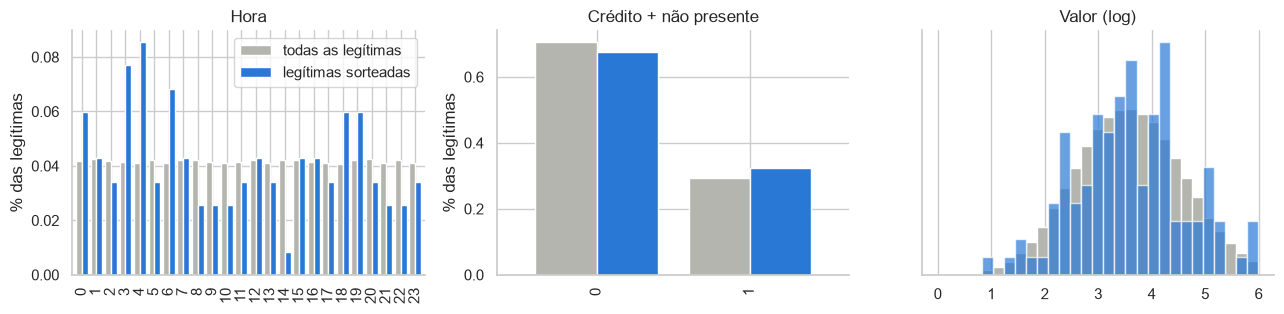

,todas as legítimas,legítimas sorteadas
amount,60.29,63.24
acceptor_risk,20.04,21.05
hora,11.49,10.4
cnp_credito,0.29,0.32


In [7]:
todas_legit = base[base[ALVO] == 0]
amostra_legit = treino_bal[treino_bal[ALVO] == 0]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, col, titulo in [(axes[0], "hora", "Hora"), (axes[1], "cnp_credito", "Crédito + não presente")]:
    pd.DataFrame({"todas as legítimas": todas_legit[col].value_counts(normalize=True),
                  "legítimas sorteadas": amostra_legit[col].value_counts(normalize=True)}).sort_index() \
      .plot.bar(ax=ax, color=["#b5b5af", COR_LEGIT], width=0.8, legend=(col == "hora"))
    ax.set(title=titulo, ylabel="% das legítimas", xlabel="")
bins = np.linspace(0, np.log1p(todas_legit.amount.quantile(0.99)), 30)
axes[2].hist(np.log1p(todas_legit.amount.dropna()), bins=bins, density=True, color="#b5b5af", label="todas")
axes[2].hist(np.log1p(amostra_legit.amount.dropna()), bins=bins, density=True, color=COR_LEGIT, alpha=0.7, label="sorteadas")
axes[2].set(title="Valor (log)", yticks=[])
plt.tight_layout(); plt.show()

comp = pd.DataFrame({"todas as legítimas": todas_legit[["amount", "acceptor_risk", "hora", "cnp_credito"]].mean(),
                     "legítimas sorteadas": amostra_legit[["amount", "acceptor_risk", "hora", "cnp_credito"]].mean()})
comp.round(2)

**Leitura:** com só ~117 legítimas, a amostra oscila. Diferenças pequenas são normais; diferenças grandes indicam que vale testar outras sementes ou usar `RAZAO_LEGIT_POR_FRAUDE = 5` (mais legítimas, menos oscilação).

## 6. Retrato da base balanceada

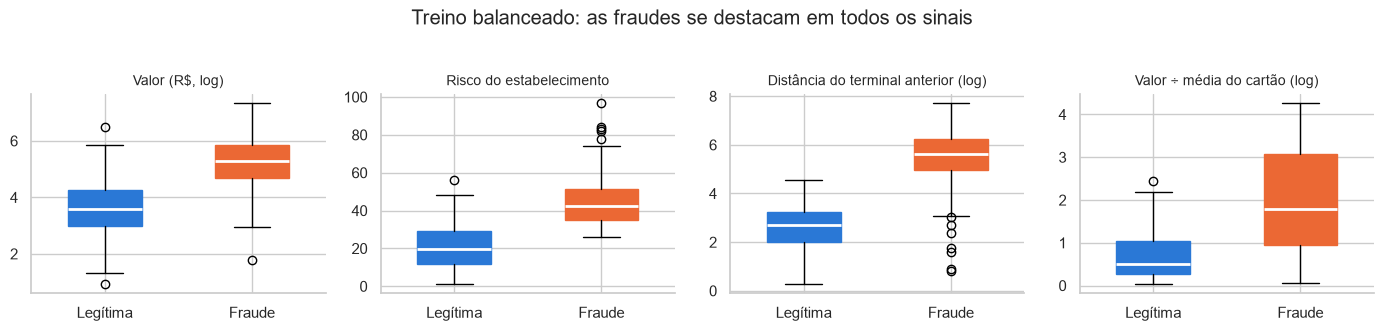

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
grupos = {0: ("Legítima", COR_LEGIT), 1: ("Fraude", COR_FRAUDE)}
for ax, col, titulo in [(axes[0], "amount", "Valor (R$, log)"), (axes[1], "acceptor_risk", "Risco do estabelecimento"),
                        (axes[2], "cp_card_prev_term_dist_1h", "Distância do terminal anterior (log)"),
                        (axes[3], "valor_vs_media_cartao", "Valor ÷ média do cartão (log)")]:
    dados = [np.log1p(treino_bal.loc[treino_bal[ALVO] == k, col].dropna()) if "log" in titulo
             else treino_bal.loc[treino_bal[ALVO] == k, col].dropna() for k in (0, 1)]
    bp = ax.boxplot(dados, tick_labels=["Legítima", "Fraude"], patch_artist=True, widths=0.5,
                    medianprops={"color": "white", "lw": 2})
    for patch, k in zip(bp["boxes"], (0, 1)):
        patch.set_facecolor(grupos[k][1]); patch.set_edgecolor(grupos[k][1])
    ax.set_title(titulo, fontsize=10)
fig.suptitle("Treino balanceado: as fraudes se destacam em todos os sinais", y=1.03)
plt.tight_layout(); plt.show()

In [9]:
pd.crosstab(treino_bal.madrugada, treino_bal[ALVO], margins=True).rename(columns={0: "legítima", 1: "fraude"})

feedback_label,legítima,fraude,All
madrugada,,,
0,82,0,82
1,35,117,152
All,117,117,234


## 7. Salvar

In [10]:
colunas_saida = IDS + FEATURES + SCORES_EXTERNOS + [ALVO]
treino_bal[colunas_saida].to_csv(PROC / "treino_balanceado.csv", index=False)
teste[colunas_saida].to_csv(PROC / "teste_proporcao_real.csv", index=False)

pd.DataFrame([
    {"coluna": c, "tipo": "feature", "grupo": g} for g, cols in FEATURES_ORIGINAIS.items() for c in cols
] + [{"coluna": c, "tipo": "feature", "grupo": "criada no notebook 02"} for c in FEATURES_NOVAS]
  + [{"coluna": c, "tipo": "baseline (não usar como feature)", "grupo": "score externo"} for c in SCORES_EXTERNOS]
  + [{"coluna": c, "tipo": "identificador (não usar como feature)", "grupo": "id"} for c in IDS]
  + [{"coluna": ALVO, "tipo": "alvo", "grupo": "alvo"}]
).to_csv(PROC / "dicionario_base_modelo.csv", index=False)

for f in sorted(PROC.iterdir()):
    print(f"{f.name:32s} {f.stat().st_size/1e6:7.2f} MB")

dicionario_base_modelo.csv          0.00 MB
teste_proporcao_real.csv            7.75 MB
treino_balanceado.csv               0.06 MB


**Arquivos gerados (`data/processed/`):**
- `treino_balanceado.csv`: para **treinar** (1:1).
- `teste_proporcao_real.csv`: para **avaliar** (~0,1% de fraude). Nunca usar no treino.
- `dicionario_base_modelo.csv`: o papel de cada coluna.

**Lembretes para a modelagem:**
1. Os nulos ainda **não** foram preenchidos: a imputação deve ser ajustada **no treino** e aplicada no teste.
2. Treinado em base 50/50, o modelo "acha" que fraude é comum: a probabilidade sai inflada. Escolham o limiar de corte olhando o teste real (precisão × recall).
3. Comparar o modelo com e sem as features pré-calculadas de velocidade/distância, e com o `fraud_score` como baseline.